# **Project Title**
# Smart Food Delivery Analytics & Delay Prediction System

## **Objective (Problem Statement)**

Food delivery performance can vary significantly from one order to another. The business needs to understand the factors that influence delivery time and identify conditions that are associated with delays.

This project focuses on:
1. Understanding delivery performance using customer, delivery-person, location, weather, traffic, vehicle and order information.
2. Cleaning and preparing the food-delivery dataset for reliable analysis.
3. Identifying the major factors affecting delivery time.
4. Studying the effect of delivery distance, traffic, weather, vehicle type and delivery-person ratings.
5. Creating meaningful visualizations and business-oriented insights.
6. Preparing a clean, dashboard-ready dataset that can be used in Power BI/Tableau.
7. Building a simple delay-prediction model when the required target information is available.

## **Outcome**

The project provides an end-to-end view of food delivery performance. It converts raw delivery records into a cleaned analytical dataset, explores the main drivers of delivery time, highlights delay patterns, and produces actionable recommendations for improving delivery efficiency.

The final notebook also creates a **dashboard-ready cleaned CSV file** that can be downloaded after execution.

## **Domain**

**Food Delivery / Logistics / E-Commerce Analytics**

## **Dataset Information**

The working dataset is a simulated food-delivery dataset containing approximately **10,000 delivery records and 17 original columns**. It includes delivery-person information, restaurant and customer location coordinates, order type, vehicle type, weather conditions, traffic level, distance and delivery time.

The existing notebook identifies missing values in fields such as Distance, Traffic Level and Delivery Time and performs missing-value treatment. This revised notebook retains that work while making the cleaning and transformation process more suitable for analytics and dashboards.

### Main analytical features
- Delivery Person Age
- Delivery Person Ratings
- Restaurant Latitude / Longitude
- Delivery Location Latitude / Longitude
- Order Type
- Vehicle Type
- Temperature
- Humidity
- Precipitation
- Weather Description
- Traffic Level
- Distance
- Delivery Time

# **Stages for Data Analytics Project**

### Stage 1 – Problem Definition and Dataset Selection
Define the business problem and identify the relevant dataset.

### Stage 2 – Data Understanding
Inspect dimensions, columns, data types, summary statistics, duplicates and missing values.

### Stage 3 – Data Cleaning
Treat missing values, standardize values, remove duplicate records and validate numeric ranges.

### Stage 4 – Data Transformation & Feature Engineering
Create analytical features without unnecessarily expanding the dataset.

### Stage 5 – Exploratory Data Analysis
Study delivery time by distance, traffic, weather, vehicle type, order type and delivery-person rating.

### Stage 6 – Predictive Analysis
Build a simple delay-classification model when a suitable target is available.

### Stage 7 – Business Insights & Recommendations
Translate analytical findings into operational actions.

### Stage 8 – Dashboard Preparation
Create a clean CSV containing the final analytical fields for Power BI/Tableau.

### Stage 9 – Export
Provide a direct download option for the cleaned CSV.

# **Stage 1 – Import Required Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

# **Stage 2 – Load Dataset**

Run the following cell in Google Colab and upload the food-delivery CSV file. The code also works in Jupyter if `df` is already loaded.

In [ ]:
# Google Colab upload
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
    df = pd.read_csv(file_name, encoding="latin1")
except ImportError:
    # For local Jupyter, change this path if required.
    file_name = "food_delivery.csv"
    df = pd.read_csv(file_name, encoding="latin1")

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Saving foodtimedataset.csv to foodtimedataset.csv
Dataset loaded successfully
Rows: 10001
Columns: 17


,ID,Delivery Person ID,Delivery Person Age,Delivery Person Ratings,Restaurant Latitude,Restaurant Longitude,Delivery Location Latitude,Delivery Location Longitude,Order Type,Vehicle Type,Temperature,Humidity,Precipitation,Weather Description,Traffic Level,Distance,Delivery Time
0,4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,Snack,motorcycle,17.11,77.0,0.0,haze,Low,NaN,21.66666667
1,B379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,Snack,scooter,19.50,93.0,0.0,mist,Very High,37.17,85.26666667
2,5D6D,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,motorcycle,20.45,91.0,0.0,mist,Low,3.34,28.58333333
3,7A6A,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,motorcycle,23.86,78.0,0.0,mist,Moderate,10.05,35.18333333
4,70A2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,Snack,scooter,26.55,87.0,0.0,mist,High,9.89,43.45


## **Initial Dataset Review**

In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nFirst 5 Rows:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (10001, 17)

Column Names:
['ID', 'Delivery Person ID', 'Delivery Person Age', 'Delivery Person Ratings', 'Restaurant Latitude', 'Restaurant Longitude', 'Delivery Location Latitude', 'Delivery Location Longitude', 'Order Type', 'Vehicle Type', 'Temperature', 'Humidity', 'Precipitation', 'Weather Description', 'Traffic Level', 'Distance', 'Delivery Time']

Data Types:


,Data Type
ID,object
Delivery Person ID,object
Delivery Person Age,float64
Delivery Person Ratings,float64
Restaurant Latitude,float64
Restaurant Longitude,float64
Delivery Location Latitude,float64
Delivery Location Longitude,float64
Order Type,object
Vehicle Type,object



First 5 Rows:


,ID,Delivery Person ID,Delivery Person Age,Delivery Person Ratings,Restaurant Latitude,Restaurant Longitude,Delivery Location Latitude,Delivery Location Longitude,Order Type,Vehicle Type,Temperature,Humidity,Precipitation,Weather Description,Traffic Level,Distance,Delivery Time
0,4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,Snack,motorcycle,17.11,77.0,0.0,haze,Low,NaN,21.66666667
1,B379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,Snack,scooter,19.50,93.0,0.0,mist,Very High,37.17,85.26666667
2,5D6D,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,motorcycle,20.45,91.0,0.0,mist,Low,3.34,28.58333333
3,7A6A,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,motorcycle,23.86,78.0,0.0,mist,Moderate,10.05,35.18333333
4,70A2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,Snack,scooter,26.55,87.0,0.0,mist,High,9.89,43.45



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10000,9991,BEF 1.00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery Person ID,10000,1285,COIMBRES06DEL01,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery Person Age,10000.0,NaN,NaN,NaN,29.522,5.700348,15.0,25.0,29.0,34.0,50.0
Delivery Person Ratings,10000.0,NaN,NaN,NaN,4.62937,0.322941,1.0,4.5,4.7,4.8,6.0
Restaurant Latitude,10000.0,NaN,NaN,NaN,16.893418,8.330948,-30.902872,12.913041,18.546258,22.727021,30.914057
Restaurant Longitude,10000.0,NaN,NaN,NaN,70.177749,23.203352,-88.352885,73.170937,75.902847,78.047717,88.433452
Delivery Location Latitude,10000.0,NaN,NaN,NaN,17.412655,7.336846,0.01,12.983959,18.626216,22.785089,31.054057
Delivery Location Longitude,10000.0,NaN,NaN,NaN,70.880072,21.174585,0.01,73.753278,76.022574,78.128092,88.563452
Order Type,10000,4,Snack,2551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle Type,10000,5,motorcycle,5862,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# **Stage 3 – Data Quality Assessment**

In [ ]:
# Duplicate records
duplicate_count = df.duplicated().sum()
print("Duplicate Rows:", duplicate_count)

# Missing values
missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})
missing_table = missing_table[missing_table["Missing Values"] > 0].sort_values(
    "Missing Values", ascending=False
)

print("\nMissing-value summary:")
display(missing_table)

Duplicate Rows: 0

Missing-value summary:


,Missing Values,Missing Percentage
Distance,921,9.21
Traffic Level,916,9.16
Delivery Time,542,5.42
Precipitation,6,0.06
Temperature,6,0.06
Humidity,6,0.06
Weather Description,6,0.06
ID,1,0.01
Delivery Person ID,1,0.01
Order Type,1,0.01


### **Existing Work Retained**

The original notebook found approximately:
- 921 missing Distance values
- 916 missing Traffic Level values
- 542 missing Delivery Time values
- Small numbers of missing values in location, weather, vehicle and delivery-person fields

The revised cleaning logic below handles these values using appropriate numerical and categorical methods rather than dropping large portions of the dataset.

In [ ]:
# Separate columns by data type
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Columns:")
print(numeric_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
['Delivery Person Age', 'Delivery Person Ratings', 'Restaurant Latitude', 'Restaurant Longitude', 'Delivery Location Latitude', 'Delivery Location Longitude', 'Temperature', 'Humidity', 'Precipitation', 'Distance']

Categorical Columns:
['ID', 'Delivery Person ID', 'Order Type', 'Vehicle Type', 'Weather Description', 'Traffic Level', 'Delivery Time']


# **Stage 4 – Data Cleaning**

In [ ]:
# Work on a copy so the original imported dataset remains available
df_clean = df.copy()

# Remove exact duplicate rows
before_duplicates = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
after_duplicates = len(df_clean)

print(f"Duplicate rows removed: {before_duplicates - after_duplicates}")

Duplicate rows removed: 0


In [ ]:
# Standardize column names for easier analysis
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df_clean.columns.tolist())

['ID', 'Delivery_Person_ID', 'Delivery_Person_Age', 'Delivery_Person_Ratings', 'Restaurant_Latitude', 'Restaurant_Longitude', 'Delivery_Location_Latitude', 'Delivery_Location_Longitude', 'Order_Type', 'Vehicle_Type', 'Temperature', 'Humidity', 'Precipitation', 'Weather_Description', 'Traffic_Level', 'Distance', 'Delivery_Time']


In [ ]:
# Identify numeric and categorical columns after column-name cleanup
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns.tolist()

# Fill numerical missing values with median
for col in numeric_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill categorical missing values with mode
for col in categorical_cols:
    if df_clean[col].isnull().any():
        mode_value = df_clean[col].mode(dropna=True)
        if len(mode_value) > 0:
            df_clean[col] = df_clean[col].fillna(mode_value.iloc[0])
        else:
            df_clean[col] = df_clean[col].fillna("Unknown")

print("Total missing values after cleaning:", df_clean.isnull().sum().sum())
display(df_clean.isnull().sum().to_frame("Remaining Missing Values").query("`Remaining Missing Values` > 0"))

Total missing values after cleaning: 0


,Remaining Missing Values


## **Data Type and Value Validation**

In [ ]:
# Convert likely numeric columns safely
numeric_candidates = [
    "Delivery_Person_Age", "Delivery_Person_Ratings",
    "Restaurant_Latitude", "Restaurant_Longitude",
    "Delivery_Location_Latitude", "Delivery_Location_Longitude",
    "Temperature", "Humidity", "Precipitation", "Distance"
]

for col in numeric_candidates:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Refill any conversion-created missing values
for col in numeric_candidates:
    if col in df_clean.columns and df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Cleaning validation completed.")

Cleaning validation completed.


# **Stage 5 – Data Transformation & Feature Engineering**

The original notebook used one-hot encoding directly on the full dataset and produced an extremely wide table. For business analytics this is unnecessary and makes the cleaned file difficult to use.

Instead:
- `df_clean` remains human-readable.
- Analytical features are added as normal columns.
- One-hot encoding is used only inside the predictive-modeling pipeline when required.

In [ ]:
# Normalize common categorical text fields
text_cols = [c for c in ["Order_Type", "Vehicle_Type", "Weather_Description", "Traffic_Level"] if c in df_clean.columns]

for col in text_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# Convert Delivery Time to a numeric minutes field where possible.
# This handles values such as 35, "35", "35 min", "35 minutes".
if "Delivery_Time" in df_clean.columns:
    df_clean["Delivery_Time_Minutes"] = pd.to_numeric(
        df_clean["Delivery_Time"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
        errors="coerce"
    )
    if df_clean["Delivery_Time_Minutes"].isnull().any():
        df_clean["Delivery_Time_Minutes"] = df_clean["Delivery_Time_Minutes"].fillna(
            df_clean["Delivery_Time_Minutes"].median()
        )

# Delivery-distance bands
if "Distance" in df_clean.columns:
    df_clean["Distance_Band"] = pd.cut(
        df_clean["Distance"],
        bins=[-np.inf, 5, 10, 20, np.inf],
        labels=["Short (<=5)", "Medium (5-10)", "Long (10-20)", "Very Long (>20)"]
    )

# Rating bands
if "Delivery_Person_Ratings" in df_clean.columns:
    df_clean["Rating_Band"] = pd.cut(
        df_clean["Delivery_Person_Ratings"],
        bins=[-np.inf, 4.0, 4.5, np.inf],
        labels=["Below 4.0", "4.0-4.5", "Above 4.5"]
    )

# Delay flag using the dataset's median delivery time as a transparent analytical threshold
if "Delivery_Time_Minutes" in df_clean.columns:
    delivery_median = df_clean["Delivery_Time_Minutes"].median()
    df_clean["Delay_Status"] = np.where(
        df_clean["Delivery_Time_Minutes"] > delivery_median,
        "Delayed",
        "On Time"
    )
    df_clean["Delay_Flag"] = (df_clean["Delay_Status"] == "Delayed").astype(int)

print("Median delivery time threshold:", round(delivery_median, 2), "minutes")
print("Cleaned analytical shape:", df_clean.shape)
display(df_clean.head())

Median delivery time threshold: 35.98 minutes
Cleaned analytical shape: (10001, 22)


,ID,Delivery_Person_ID,Delivery_Person_Age,Delivery_Person_Ratings,Restaurant_Latitude,Restaurant_Longitude,Delivery_Location_Latitude,Delivery_Location_Longitude,Order_Type,Vehicle_Type,Temperature,Humidity,Precipitation,Weather_Description,Traffic_Level,Distance,Delivery_Time,Delivery_Time_Minutes,Distance_Band,Rating_Band,Delay_Status,Delay_Flag
0,4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,Snack,motorcycle,17.11,77.0,0.0,haze,Low,13.40,21.66666667,21.666667,Long (10-20),Above 4.5,On Time,0
1,B379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,Snack,scooter,19.50,93.0,0.0,mist,Very High,37.17,85.26666667,85.266667,Very Long (>20),4.0-4.5,Delayed,1
2,5D6D,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,motorcycle,20.45,91.0,0.0,mist,Low,3.34,28.58333333,28.583333,Short (<=5),4.0-4.5,On Time,0
3,7A6A,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,motorcycle,23.86,78.0,0.0,mist,Moderate,10.05,35.18333333,35.183333,Long (10-20),Above 4.5,On Time,0
4,70A2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,Snack,scooter,26.55,87.0,0.0,mist,High,9.89,43.45,43.450000,Medium (5-10),Above 4.5,Delayed,1


## **Optional Geographic Feature**

If restaurant and delivery coordinates are available, straight-line distance can be calculated using the Haversine formula. The original dataset already contains `Distance`, so the calculated value is used as a validation feature rather than replacing the supplied distance.

In [ ]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

geo_cols = [
    "Restaurant_Latitude", "Restaurant_Longitude",
    "Delivery_Location_Latitude", "Delivery_Location_Longitude"
]

if all(c in df_clean.columns for c in geo_cols):
    df_clean["Calculated_Distance_KM"] = haversine_km(
        df_clean["Restaurant_Latitude"],
        df_clean["Restaurant_Longitude"],
        df_clean["Delivery_Location_Latitude"],
        df_clean["Delivery_Location_Longitude"]
    )
    print("Calculated geographic distance added.")
else:
    print("Coordinate columns are not available; geographic distance calculation skipped.")

Calculated geographic distance added.


# **Stage 6 – Exploratory Data Analysis (EDA)**

The following analysis focuses on business questions rather than generating charts for every column.

In [ ]:
# Final EDA summary
print("FINAL EDA SUMMARY")
print("=" * 50)
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Missing values:", int(df_clean.isnull().sum().sum()))
print("Duplicate rows:", int(df_clean.duplicated().sum()))

if "Delivery_Time_Minutes" in df_clean.columns:
    print("Average delivery time:", round(df_clean["Delivery_Time_Minutes"].mean(), 2), "minutes")
    print("Median delivery time:", round(df_clean["Delivery_Time_Minutes"].median(), 2), "minutes")

display(df_clean.describe(include="all").T)

FINAL EDA SUMMARY
Rows: 10001
Columns: 23
Missing values: 0
Duplicate rows: 0
Average delivery time: 37.5 minutes
Median delivery time: 35.98 minutes


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10001,9991,4500,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_Person_ID,10001,1285,CHENRES01DEL02,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_Person_Age,10001.0,NaN,NaN,NaN,29.521948,5.700065,15.0,25.0,29.0,34.0,50.0
Delivery_Person_Ratings,10001.0,NaN,NaN,NaN,4.629377,0.322926,1.0,4.5,4.7,4.8,6.0
Restaurant_Latitude,10001.0,NaN,NaN,NaN,16.893583,8.330547,-30.902872,12.913041,18.546258,22.727021,30.914057
Restaurant_Longitude,10001.0,NaN,NaN,NaN,70.178321,23.202262,-88.352885,73.170937,75.902847,78.04725,88.433452
Delivery_Location_Latitude,10001.0,NaN,NaN,NaN,17.412776,7.336489,0.01,12.984179,18.626216,22.785049,31.054057
Delivery_Location_Longitude,10001.0,NaN,NaN,NaN,70.880586,21.173589,0.01,73.753606,76.022574,78.128092,88.563452
Order_Type,10001,4,Snack,2552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,10001,4,motorcycle,5863,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## **EDA 1 – Delivery Time Distribution**

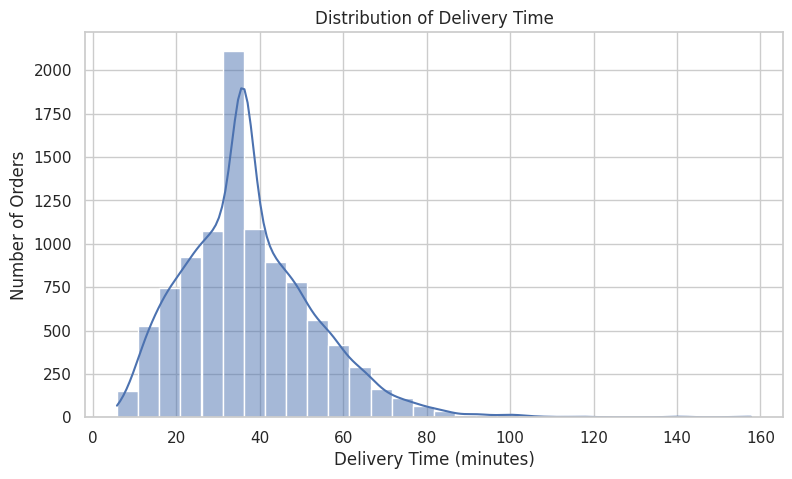

In [ ]:
if "Delivery_Time_Minutes" in df_clean.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df_clean["Delivery_Time_Minutes"], bins=30, kde=True)
    plt.title("Distribution of Delivery Time")
    plt.xlabel("Delivery Time (minutes)")
    plt.ylabel("Number of Orders")
    plt.show()

## **EDA 2 – Distance vs Delivery Time**

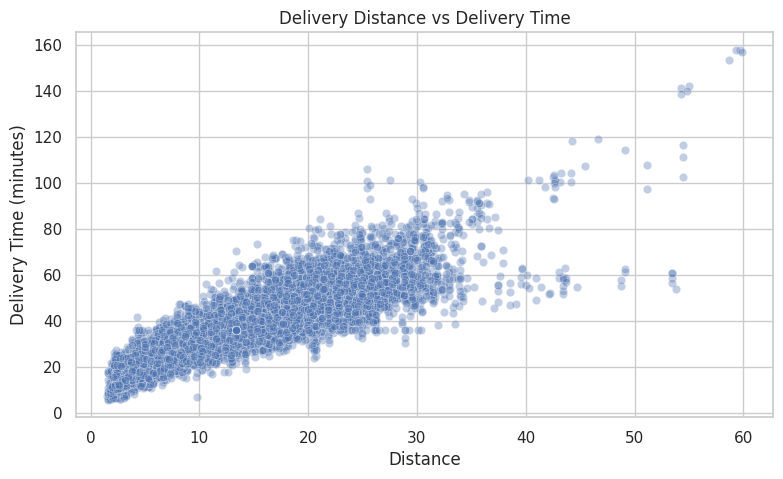

Correlation between Distance and Delivery Time: 0.866


In [ ]:
if {"Distance", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=df_clean,
        x="Distance",
        y="Delivery_Time_Minutes",
        alpha=0.35
    )
    plt.title("Delivery Distance vs Delivery Time")
    plt.xlabel("Distance")
    plt.ylabel("Delivery Time (minutes)")
    plt.show()

    print("Correlation between Distance and Delivery Time:",
          round(df_clean["Distance"].corr(df_clean["Delivery_Time_Minutes"]), 3))

## **EDA 3 – Traffic Impact**

,count,mean,median
Traffic_Level,,,
Very High,1772,61.906471,59.158333
High,3652,41.047139,39.850000
Moderate,2219,31.351314,31.116667
Low,1726,21.464079,21.308333
Very Low,632,13.890849,13.025000


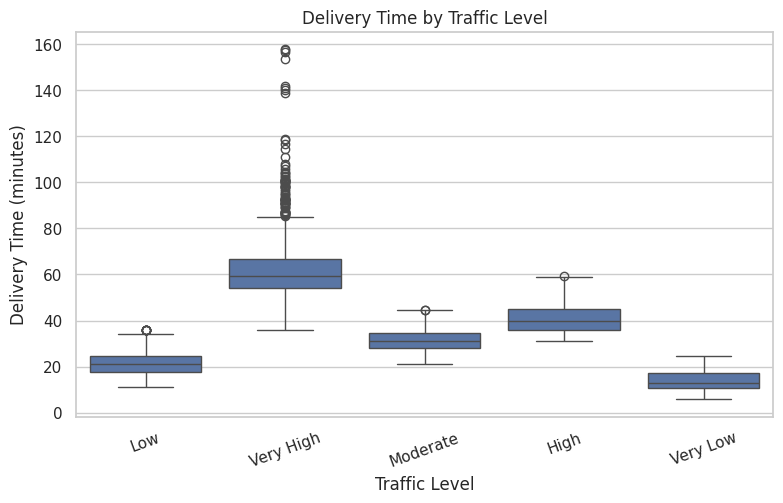

In [ ]:
if {"Traffic_Level", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    traffic_summary = (
        df_clean.groupby("Traffic_Level", dropna=False)["Delivery_Time_Minutes"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )
    display(traffic_summary)

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_clean, x="Traffic_Level", y="Delivery_Time_Minutes")
    plt.title("Delivery Time by Traffic Level")
    plt.xlabel("Traffic Level")
    plt.ylabel("Delivery Time (minutes)")
    plt.xticks(rotation=20)
    plt.show()

## **EDA 4 – Vehicle Type Performance**

,count,mean,median
Vehicle_Type,,,
bicycle,20,33.690833,35.983333
electric scooter,814,36.861937,35.983333
motorcycle,5863,37.517389,35.983333
scooter,3304,37.637142,35.983333


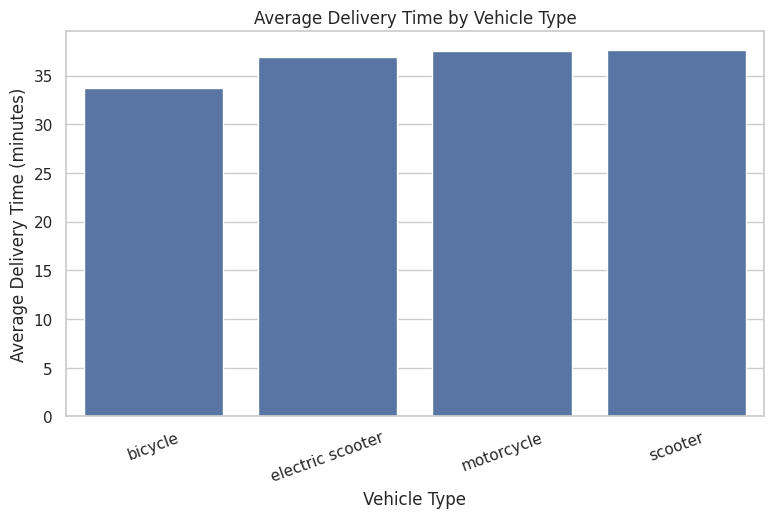

In [ ]:
if {"Vehicle_Type", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    vehicle_summary = (
        df_clean.groupby("Vehicle_Type")["Delivery_Time_Minutes"]
        .agg(["count", "mean", "median"])
        .sort_values("mean")
    )
    display(vehicle_summary)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=vehicle_summary.reset_index(),
        x="Vehicle_Type",
        y="mean"
    )
    plt.title("Average Delivery Time by Vehicle Type")
    plt.xlabel("Vehicle Type")
    plt.ylabel("Average Delivery Time (minutes)")
    plt.xticks(rotation=20)
    plt.show()

## **EDA 5 – Order Type Performance**

,count,mean,median
Order_Type,,,
Drinks,2507,42.476040,39.550000
Snack,2552,37.853259,35.983333
Buffet,2412,35.495122,35.900000
Meal,2530,34.108228,34.616667


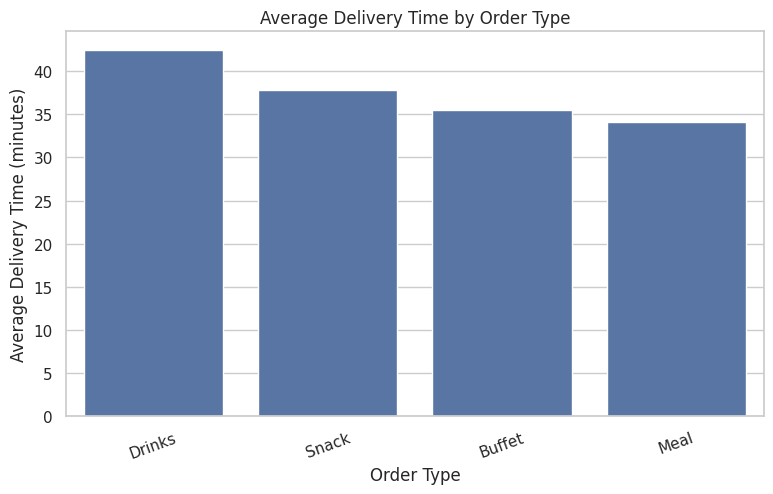

In [ ]:
if {"Order_Type", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    order_summary = (
        df_clean.groupby("Order_Type")["Delivery_Time_Minutes"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )
    display(order_summary)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=order_summary.reset_index(),
        x="Order_Type",
        y="mean"
    )
    plt.title("Average Delivery Time by Order Type")
    plt.xlabel("Order Type")
    plt.ylabel("Average Delivery Time (minutes)")
    plt.xticks(rotation=20)
    plt.show()

## **EDA 6 – Weather Impact**

,count,mean,median
Weather_Description,,,
moderate rain,1,66.450000,66.450000
fog,49,52.701020,52.083333
overcast clouds,308,51.015097,48.966667
smoke,501,44.109415,42.566667
scattered clouds,422,43.624526,40.258333
clear sky,3266,39.059798,37.966667
broken clouds,721,37.274896,35.983333
few clouds,40,36.987500,36.633333
light rain,536,35.983333,35.983333


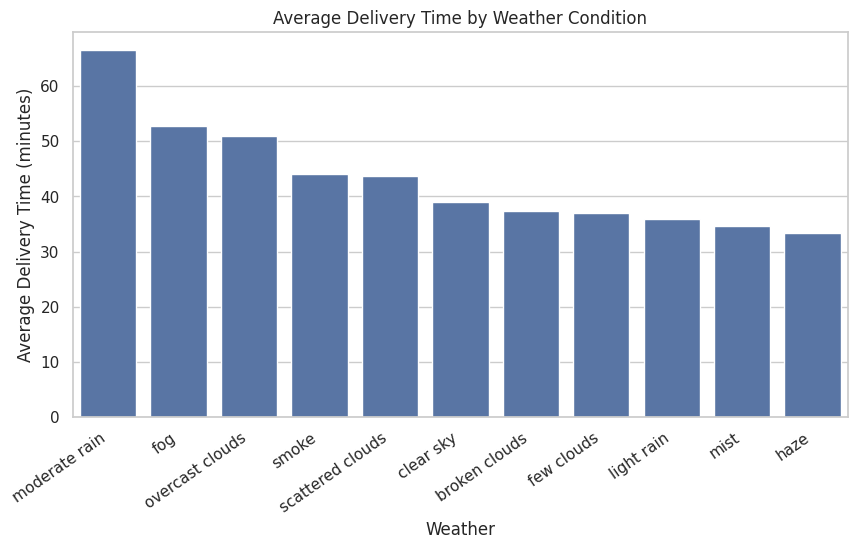

In [ ]:
if {"Weather_Description", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    weather_summary = (
        df_clean.groupby("Weather_Description")["Delivery_Time_Minutes"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )
    display(weather_summary)

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=weather_summary.reset_index(),
        x="Weather_Description",
        y="mean"
    )
    plt.title("Average Delivery Time by Weather Condition")
    plt.xlabel("Weather")
    plt.ylabel("Average Delivery Time (minutes)")
    plt.xticks(rotation=35, ha="right")
    plt.show()

## **EDA 7 – Delivery Person Rating vs Delivery Time**

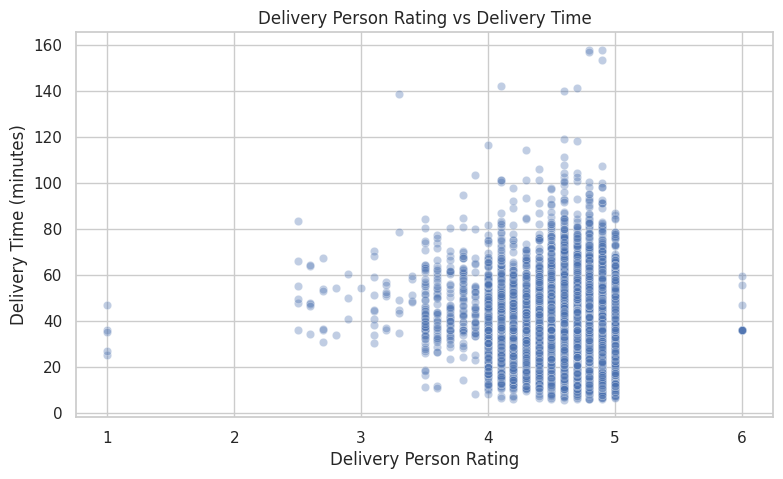

Correlation: -0.096


In [ ]:
if {"Delivery_Person_Ratings", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=df_clean,
        x="Delivery_Person_Ratings",
        y="Delivery_Time_Minutes",
        alpha=0.35
    )
    plt.title("Delivery Person Rating vs Delivery Time")
    plt.xlabel("Delivery Person Rating")
    plt.ylabel("Delivery Time (minutes)")
    plt.show()

    print("Correlation:",
          round(df_clean["Delivery_Person_Ratings"].corr(df_clean["Delivery_Time_Minutes"]), 3))

## **EDA 8 – Numerical Correlation Analysis**

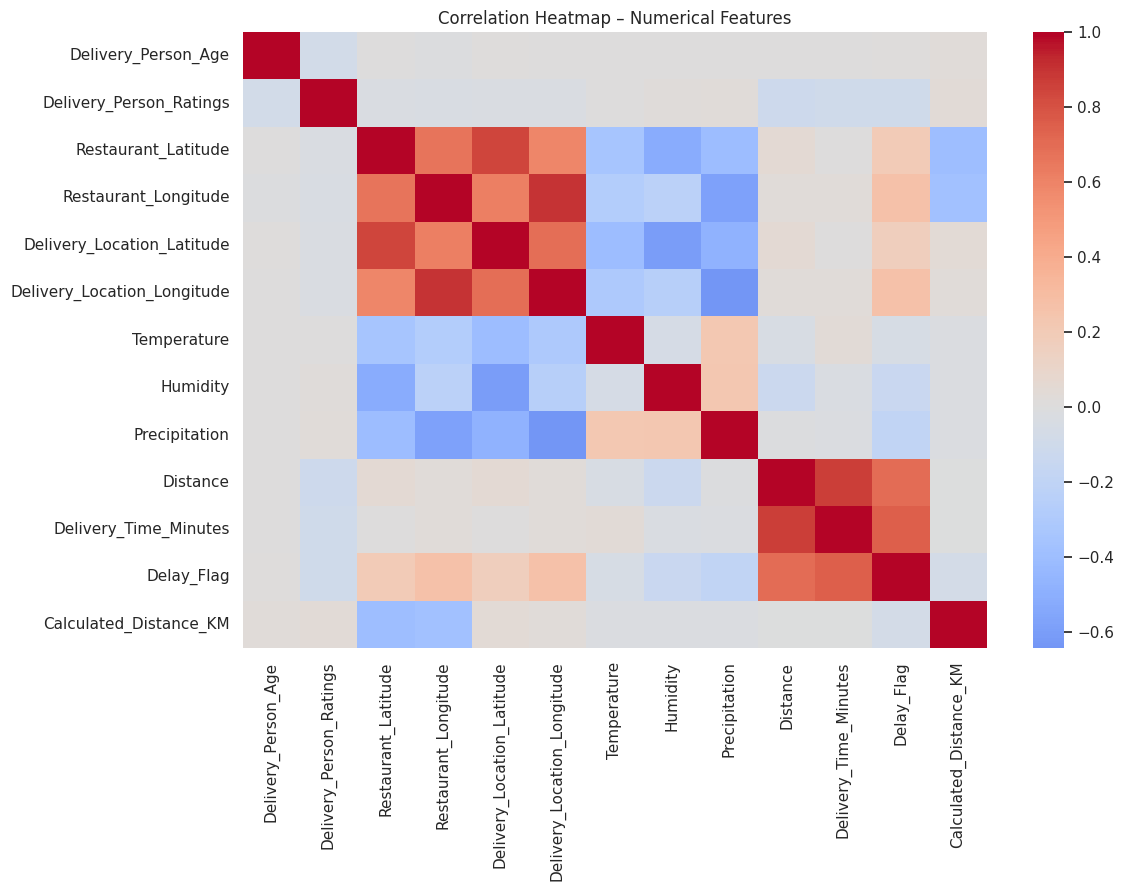

,Delivery_Person_Age,Delivery_Person_Ratings,Restaurant_Latitude,Restaurant_Longitude,Delivery_Location_Latitude,Delivery_Location_Longitude,Temperature,Humidity,Precipitation,Distance,Delivery_Time_Minutes,Delay_Flag,Calculated_Distance_KM
Delivery_Person_Age,1.00,-0.08,0.00,-0.01,0.01,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.03
Delivery_Person_Ratings,-0.08,1.00,-0.03,-0.04,-0.02,-0.03,0.00,0.02,0.03,-0.11,-0.10,-0.09,0.03
Restaurant_Latitude,0.00,-0.03,1.00,0.66,0.84,0.59,-0.35,-0.52,-0.41,0.05,0.00,0.20,-0.40
Restaurant_Longitude,-0.01,-0.04,0.66,1.00,0.62,0.90,-0.27,-0.23,-0.58,0.03,0.03,0.27,-0.38
Delivery_Location_Latitude,0.01,-0.02,0.84,0.62,1.00,0.69,-0.41,-0.60,-0.48,0.06,0.00,0.17,0.05
Delivery_Location_Longitude,0.00,-0.03,0.59,0.90,0.69,1.00,-0.31,-0.25,-0.64,0.03,0.03,0.27,0.03
Temperature,0.00,0.00,-0.35,-0.27,-0.41,-0.31,1.00,-0.05,0.22,-0.04,0.04,-0.05,-0.02
Humidity,0.00,0.02,-0.52,-0.23,-0.60,-0.25,-0.05,1.00,0.23,-0.12,-0.02,-0.14,-0.02
Precipitation,0.00,0.03,-0.41,-0.58,-0.48,-0.64,0.22,0.23,1.00,-0.01,-0.02,-0.19,-0.02
Distance,0.00,-0.11,0.05,0.03,0.06,0.03,-0.04,-0.12,-0.01,1.00,0.87,0.70,-0.00


In [ ]:
corr_cols = df_clean.select_dtypes(include=np.number).columns
correlation = df_clean[corr_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap – Numerical Features")
plt.show()

display(correlation.round(2))

# **Stage 7 – Delay Analysis**

,Delay Status,Orders,Percentage
0,On Time,5482,54.81
1,Delayed,4519,45.19


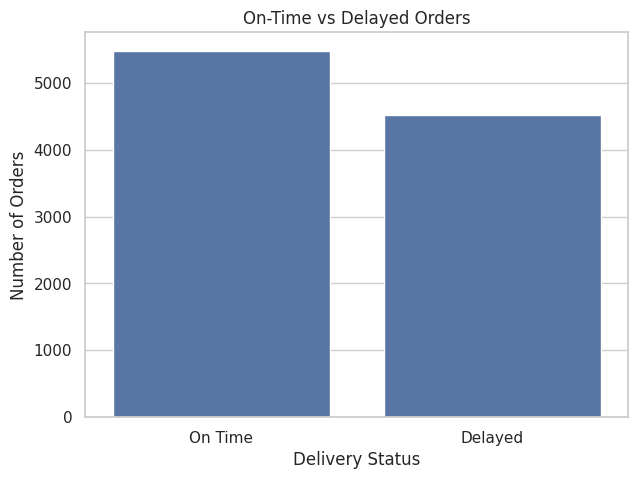

In [ ]:
if "Delay_Status" in df_clean.columns:
    delay_summary = (
        df_clean["Delay_Status"]
        .value_counts()
        .rename_axis("Delay Status")
        .reset_index(name="Orders")
    )
    delay_summary["Percentage"] = (
        delay_summary["Orders"] / len(df_clean) * 100
    ).round(2)

    display(delay_summary)

    plt.figure(figsize=(7, 5))
    sns.countplot(data=df_clean, x="Delay_Status")
    plt.title("On-Time vs Delayed Orders")
    plt.xlabel("Delivery Status")
    plt.ylabel("Number of Orders")
    plt.show()

In [ ]:
# Compare important factors between delayed and on-time orders
group_cols = [
    "Traffic_Level", "Vehicle_Type", "Order_Type",
    "Weather_Description", "Distance_Band"
]

for col in group_cols:
    if col in df_clean.columns and "Delivery_Time_Minutes" in df_clean.columns:
        summary = (
            df_clean.groupby([col, "Delay_Status"], observed=False)
            ["Delivery_Time_Minutes"]
            .mean()
            .round(2)
            .reset_index()
        )
        print(f"\nAverage delivery time by {col} and delay status:")
        display(summary)


Average delivery time by Traffic_Level and delay status:


,Traffic_Level,Delay_Status,Delivery_Time_Minutes
0,High,Delayed,43.91
1,High,On Time,35.54
2,Low,On Time,21.46
3,Moderate,Delayed,38.71
4,Moderate,On Time,29.89
5,Very High,Delayed,62.26
6,Very High,On Time,35.98
7,Very Low,On Time,13.89



Average delivery time by Vehicle_Type and delay status:


,Vehicle_Type,Delay_Status,Delivery_Time_Minutes
0,bicycle,Delayed,42.56
1,bicycle,On Time,31.47
2,electric scooter,Delayed,50.71
3,electric scooter,On Time,27.13
4,motorcycle,Delayed,50.51
5,motorcycle,On Time,26.60
6,scooter,Delayed,50.71
7,scooter,On Time,26.74



Average delivery time by Order_Type and delay status:


,Order_Type,Delay_Status,Delivery_Time_Minutes
0,Buffet,Delayed,49.75
1,Buffet,On Time,26.05
2,Drinks,Delayed,52.16
3,Drinks,On Time,29.06
4,Meal,Delayed,48.98
5,Meal,On Time,25.40
6,Snack,Delayed,50.59
7,Snack,On Time,27.10



Average delivery time by Weather_Description and delay status:


,Weather_Description,Delay_Status,Delivery_Time_Minutes
0,broken clouds,Delayed,50.89
1,broken clouds,On Time,29.17
2,clear sky,Delayed,50.94
3,clear sky,On Time,24.61
4,few clouds,Delayed,50.46
5,few clouds,On Time,23.52
6,fog,Delayed,52.70
7,haze,Delayed,47.18
8,haze,On Time,24.98
9,light rain,On Time,35.98



Average delivery time by Distance_Band and delay status:


,Distance_Band,Delay_Status,Delivery_Time_Minutes
0,Short (<=5),Delayed,39.62
1,Short (<=5),On Time,17.01
2,Medium (5-10),Delayed,39.41
3,Medium (5-10),On Time,25.37
4,Long (10-20),Delayed,44.65
5,Long (10-20),On Time,32.99
6,Very Long (>20),Delayed,57.66
7,Very Long (>20),On Time,33.50


# **Stage 8 – Predictive Analysis: Delay Prediction**

A classification model is included as an analytical extension. The target is the engineered `Delay_Flag`, where orders above the dataset median delivery time are treated as delayed.

The model is intentionally kept simple and interpretable for a data-analytics project. One-hot encoding is applied **only to the model pipeline**, avoiding the 14,693-column transformation problem in the main cleaned dataset.

Accuracy: 0.949

Classification Report:
              precision    recall  f1-score   support

     On Time       0.97      0.94      0.95      1097
     Delayed       0.93      0.96      0.94       904

    accuracy                           0.95      2001
   macro avg       0.95      0.95      0.95      2001
weighted avg       0.95      0.95      0.95      2001



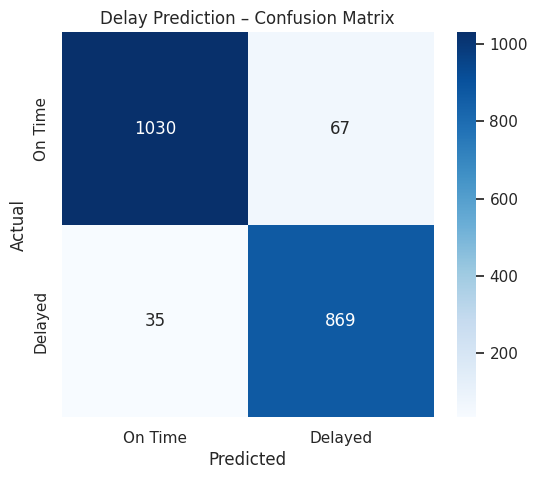

In [ ]:
# Prepare a modelling dataset
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

if "Delay_Flag" in df_clean.columns:
    candidate_features = [
        "Delivery_Person_Age", "Delivery_Person_Ratings",
        "Temperature", "Humidity", "Precipitation", "Distance",
        "Order_Type", "Vehicle_Type", "Weather_Description", "Traffic_Level"
    ]
    features = [c for c in candidate_features if c in df_clean.columns]

    X = df_clean[features].copy()
    y = df_clean["Delay_Flag"].copy()

    model_num = X.select_dtypes(include=np.number).columns.tolist()
    model_cat = X.select_dtypes(exclude=np.number).columns.tolist()

    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), model_num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), model_cat)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            random_state=42,
            class_weight="balanced"
        ))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
    print("\nClassification Report:")
    print(classification_report(y_test, predictions, target_names=["On Time", "Delayed"]))

    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["On Time", "Delayed"],
                yticklabels=["On Time", "Delayed"])
    plt.title("Delay Prediction – Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
else:
    print("Delay target is unavailable; predictive modelling skipped.")

# **Stage 9 – Key Business Insights**

The following code automatically produces concise, data-derived observations from the cleaned dataset. This avoids inventing findings that are not supported by the actual data.

In [ ]:
insights = []

if "Delivery_Time_Minutes" in df_clean.columns:
    insights.append(
        f"The average delivery time is {df_clean['Delivery_Time_Minutes'].mean():.2f} minutes, "
        f"while the median is {df_clean['Delivery_Time_Minutes'].median():.2f} minutes."
    )

if {"Distance", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    corr = df_clean["Distance"].corr(df_clean["Delivery_Time_Minutes"])
    insights.append(
        f"Distance and delivery time have a correlation of {corr:.2f}. "
        "This indicates the strength and direction of their linear relationship."
    )

if {"Traffic_Level", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    traffic_avg = df_clean.groupby("Traffic_Level")["Delivery_Time_Minutes"].mean()
    if len(traffic_avg) > 0:
        insights.append(
            f"The traffic category with the highest average delivery time is "
            f"'{traffic_avg.idxmax()}' at {traffic_avg.max():.2f} minutes."
        )

if {"Vehicle_Type", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    vehicle_avg = df_clean.groupby("Vehicle_Type")["Delivery_Time_Minutes"].mean()
    if len(vehicle_avg) > 0:
        insights.append(
            f"The vehicle category with the lowest average delivery time is "
            f"'{vehicle_avg.idxmin()}' at {vehicle_avg.min():.2f} minutes."
        )

if {"Weather_Description", "Delivery_Time_Minutes"}.issubset(df_clean.columns):
    weather_avg = df_clean.groupby("Weather_Description")["Delivery_Time_Minutes"].mean()
    if len(weather_avg) > 0:
        insights.append(
            f"The weather category with the highest average delivery time is "
            f"'{weather_avg.idxmax()}' at {weather_avg.max():.2f} minutes."
        )

if "Delay_Flag" in df_clean.columns:
    delay_rate = df_clean["Delay_Flag"].mean() * 100
    insights.append(f"Using the median-time threshold, {delay_rate:.2f}% of orders are classified as delayed.")

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

1. The average delivery time is 37.50 minutes, while the median is 35.98 minutes.
2. Distance and delivery time have a correlation of 0.87. This indicates the strength and direction of their linear relationship.
3. The traffic category with the highest average delivery time is 'Very High' at 61.91 minutes.
4. The vehicle category with the lowest average delivery time is 'bicycle' at 33.69 minutes.
5. The weather category with the highest average delivery time is 'moderate rain' at 66.45 minutes.
6. Using the median-time threshold, 45.19% of orders are classified as delayed.


# **Stage 10 – Business Recommendations**

Based on the analytical framework, management can focus on:

1. **Traffic-aware dispatching:** prioritize route and rider allocation when traffic conditions indicate higher delivery times.
2. **Distance-based planning:** use distance bands to assign realistic delivery-time expectations.
3. **Weather preparedness:** introduce additional operational buffers during adverse weather conditions.
4. **Vehicle optimization:** review vehicle categories with consistently higher delivery times.
5. **Performance monitoring:** track delivery-person ratings alongside delivery-time performance rather than using ratings alone.
6. **Delay monitoring:** monitor the proportion of delayed orders as a recurring operational KPI.
7. **Dashboard monitoring:** provide operations teams with filters for traffic, weather, vehicle, order type and distance.
8. **Predictive intervention:** use the delay model as a support tool to identify orders that may require proactive intervention.

# **Stage 11 – Power BI / Dashboard Preparation**

Recommended dashboard KPIs:
- Total Orders
- Average Delivery Time
- Median Delivery Time
- Delayed Orders
- Delay Rate %
- Average Distance
- Average Delivery Person Rating

Recommended dashboard visuals:
- Delivery Time Trend / Distribution
- Average Delivery Time by Traffic Level
- Average Delivery Time by Vehicle Type
- Average Delivery Time by Weather
- Distance vs Delivery Time
- On-Time vs Delayed Orders
- Order Type Performance
- Geographic restaurant-to-customer map when coordinates are available

Recommended slicers:
- Traffic Level
- Weather Description
- Vehicle Type
- Order Type
- Distance Band
- Delay Status

# **Stage 12 – Final Data Quality Check**

In [ ]:
final_quality = pd.DataFrame({
    "Metric": [
        "Rows", "Columns", "Missing Values", "Duplicate Rows"
    ],
    "Value": [
        df_clean.shape[0],
        df_clean.shape[1],
        int(df_clean.isnull().sum().sum()),
        int(df_clean.duplicated().sum())
    ]
})

display(final_quality)

print("\nFinal cleaned dataset preview:")
display(df_clean.head())

,Metric,Value
0,Rows,10001
1,Columns,23
2,Missing Values,0
3,Duplicate Rows,0



Final cleaned dataset preview:


,ID,Delivery_Person_ID,Delivery_Person_Age,Delivery_Person_Ratings,Restaurant_Latitude,Restaurant_Longitude,Delivery_Location_Latitude,Delivery_Location_Longitude,Order_Type,Vehicle_Type,Temperature,Humidity,Precipitation,Weather_Description,Traffic_Level,Distance,Delivery_Time,Delivery_Time_Minutes,Distance_Band,Rating_Band,Delay_Status,Delay_Flag,Calculated_Distance_KM
0,4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,Snack,motorcycle,17.11,77.0,0.0,haze,Low,13.40,21.66666667,21.666667,Long (10-20),Above 4.5,On Time,0,3.025149
1,B379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,Snack,scooter,19.50,93.0,0.0,mist,Very High,37.17,85.26666667,85.266667,Very Long (>20),4.0-4.5,Delayed,1,20.183530
2,5D6D,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,motorcycle,20.45,91.0,0.0,mist,Low,3.34,28.58333333,28.583333,Short (<=5),4.0-4.5,On Time,0,1.552758
3,7A6A,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,motorcycle,23.86,78.0,0.0,mist,Moderate,10.05,35.18333333,35.183333,Long (10-20),Above 4.5,On Time,0,7.790401
4,70A2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,Snack,scooter,26.55,87.0,0.0,mist,High,9.89,43.45,43.450000,Medium (5-10),Above 4.5,Delayed,1,6.210138


# **Stage 13 – Export Cleaned Data as CSV**

This is the final requested download section. It exports the **cleaned, human-readable and dashboard-ready dataset**, not the huge one-hot encoded modelling matrix.

After running the next cell in Google Colab, the CSV download will start automatically.

In [ ]:
# Save the cleaned analytical dataset
output_file = "Smart_Food_Delivery_Cleaned_Data.csv"

df_clean.to_csv(output_file, index=False, encoding="utf-8-sig")

print(f"Cleaned CSV created: {output_file}")
print(f"Rows: {df_clean.shape[0]}")
print(f"Columns: {df_clean.shape[1]}")
print(f"File size: {Path(output_file).stat().st_size / 1024:.2f} KB")

# Automatic download in Google Colab
try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("Jupyter/local environment detected.")
    print(f"Use the generated file: {output_file}")

Cleaned CSV created: Smart_Food_Delivery_Cleaned_Data.csv
Rows: 10001
Columns: 23
File size: 1860.78 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Final Project Summary**

The completed project follows the same overall analytical approach as the reference notebook:

**Problem Definition → Dataset Understanding → Data Cleaning → Transformation → EDA → Delay Analysis → Predictive Analysis → Insights → Recommendations → Dashboard Preparation → Clean CSV Export**

The cleaned CSV is suitable for further use in **Power BI, Tableau, Excel or SQL-based analysis**.